# Results dashboard -- solution/ (18 pipeline arms)

One notebook, not eighteen -- see the repo's own methodology on why
(`CLAUDE.md`: one canonical notebook per solution folder; per-pipeline
notebooks make "which one produced the number?" unanswerable and go stale the
moment a pipeline is re-run). Every pipeline's actual result already lives as
JSON under `solution/artifacts/runs/`; `solution/results.csv` is the
already-built cross-pipeline harvest of those files
(`solution/harvest_results.py`). This notebook only visualizes it.

Primary comparison surface: protocol `forward-with_aobt-keep_all`, seed 42 --
the protocol the file-naming (`compare_summary__forward-with_aobt-keep_all__seed42.json`)
treats as the build's main one. Other protocols/seeds are shown in later
sections for context (robustness, sensitivity), not as the headline number.


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

SOLUTION_DIR = Path("..") / "solution"
df = pd.read_csv(SOLUTION_DIR / "results.csv")
print("rows:", len(df), "| arms:", df.arm.nunique(), "| protocols:", df.protocol.nunique())
df.head()


rows: 113 | arms: 18 | protocols: 9


,owner,arm,protocol,seed,tag,val_rmse,val_inband,test_rmse,test_inband,test_trivial_mean,selection_surface,val_fitted,status
0,claude,cross_blend,forward-with_aobt-keep_all,42,w_global,253.05,234.23,265.00,241.28,523.38,NaN,NaN,has_results
1,claude,cross_blend,forward-with_aobt-keep_all,42,w_inner,250.76,231.48,243.49,222.40,523.38,forward_inner,False,has_results
2,claude,cross_blend,forward-with_aobt-keep_all,42,w_inner_tuned,250.24,231.08,243.50,222.49,523.38,forward_inner,False,has_results
3,claude,cross_blend,forward-with_aobt-keep_all,42,w_per_airport,250.34,231.44,246.38,224.27,523.38,NaN,NaN,has_results
4,claude,cross_blend,forward-with_aobt-keep_all,43,w_inner,253.11,233.08,252.31,227.81,523.38,forward_inner,False,has_results


## 1. What's in `results.csv`

In [2]:
print(df["status"].value_counts())
print()
print(df["protocol"].value_counts())


status
has_results    77
val_only       31
refit_only      5
Name: count, dtype: int64

protocol
forward-with_aobt-keep_all          52
forward_inner-with_aobt-keep_all    25
forward-with_aobt-winsor_p9999      10
forward-no_aobt-keep_all             6
seasonal-with_aobt-keep_all          6
full-with_aobt-keep_all              5
forward-with_aobt-drop_7200          3
forward-with_aobt-winsor_21600       3
forward-with_aobt-winsor_7200        3
Name: count, dtype: int64


## 2. Primary comparison: `forward-with_aobt-keep_all`, seed 42

Per arm, take its **best** (lowest val RMSE) row among rows that actually have a
reported test RMSE (`status == "has_results"`) -- this deliberately excludes
mid-sweep tuning candidates (`status == "val_only"`, e.g. the `lightgbm`
hyperparameter sweep tags) and refit-only rows (no val at all). Picking a
"winner" among val-only candidates without a subsequent honest test pass would
be exactly the test-leak gate (E3) this workspace's methodology exists to catch.


In [3]:
PRIMARY = "forward-with_aobt-keep_all"
SEED = 42

primary = df[(df.protocol == PRIMARY) & (df.seed == SEED) & (df.status == "has_results")].copy()
best = (primary.sort_values("val_rmse")
               .groupby("arm", as_index=False).first()
               .sort_values("val_rmse")
               .reset_index(drop=True))

display(best[["arm", "owner", "tag", "val_rmse", "test_rmse", "val_inband", "test_inband"]])
print(f"\nbest-on-val: {best.iloc[0]['arm']}  (val={best.iloc[0]['val_rmse']:.2f}, "
      f"test={best.iloc[0]['test_rmse']:.2f})")


,arm,owner,tag,val_rmse,test_rmse,val_inband,test_inband
0,cross_blend,claude,w_inner_tuned,250.24,243.50,231.08,222.49
1,multimodel_antigravity,antigravity,NaN,250.32,241.60,231.17,223.76
2,ensemble_antigravity,antigravity,NaN,254.40,270.36,236.10,251.62
3,mlp_antigravity,antigravity,NaN,255.20,275.14,237.12,259.71
4,per_airport_stack,claude,inner2_tuned,278.81,286.10,237.59,222.30
5,per_airport_tuned,claude,NaN,279.18,286.31,239.10,223.18
6,per_airport,claude,NaN,282.66,287.36,241.01,224.68
7,per_airport_antigravity,antigravity,NaN,282.66,287.36,241.01,224.68
8,per_airport_arrfeat,claude,NaN,282.87,287.24,242.27,224.14
9,lightgbm_arrfeat,claude,NaN,300.45,307.84,253.48,230.58



best-on-val: cross_blend  (val=250.24, test=243.50)


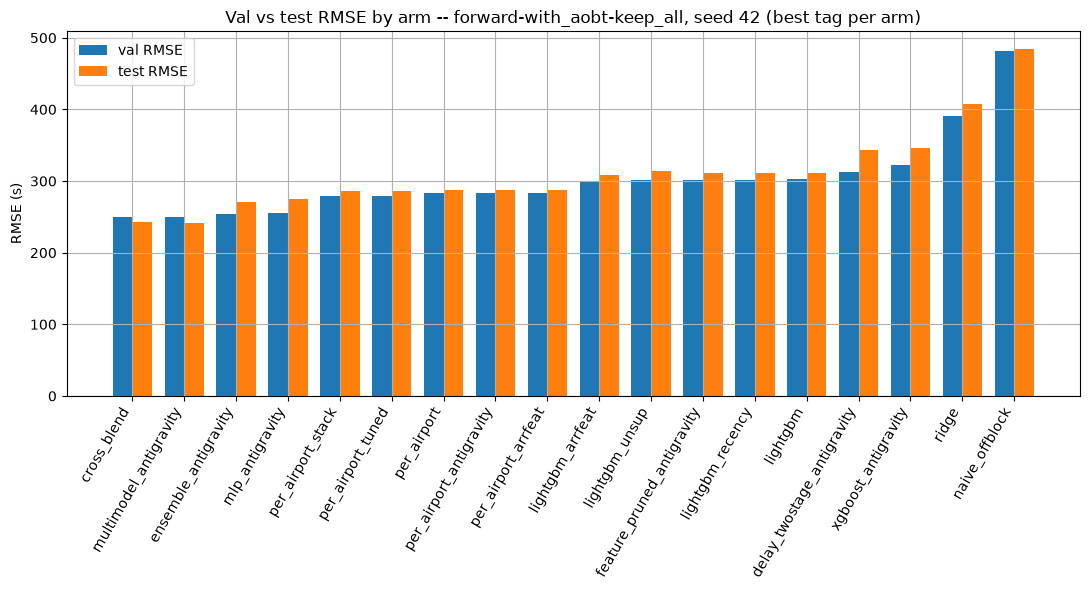

In [4]:
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(best))
w = 0.38
ax.bar(x - w/2, best["val_rmse"], width=w, label="val RMSE", color="tab:blue")
ax.bar(x + w/2, best["test_rmse"], width=w, label="test RMSE", color="tab:orange")
ax.set_xticks(x)
ax.set_xticklabels(best["arm"], rotation=60, ha="right")
ax.set_ylabel("RMSE (s)")
ax.set_title(f"Val vs test RMSE by arm -- {PRIMARY}, seed {SEED} (best tag per arm)")
ax.legend()
plt.tight_layout()
plt.show()


## 3. Val vs test -- overfitting check

Every point should sit close to the diagonal. A point well *below* the line
(test much worse than val) is the signature of a winner picked too close to
val noise; a point well *above* it is unusual but not itself a problem.


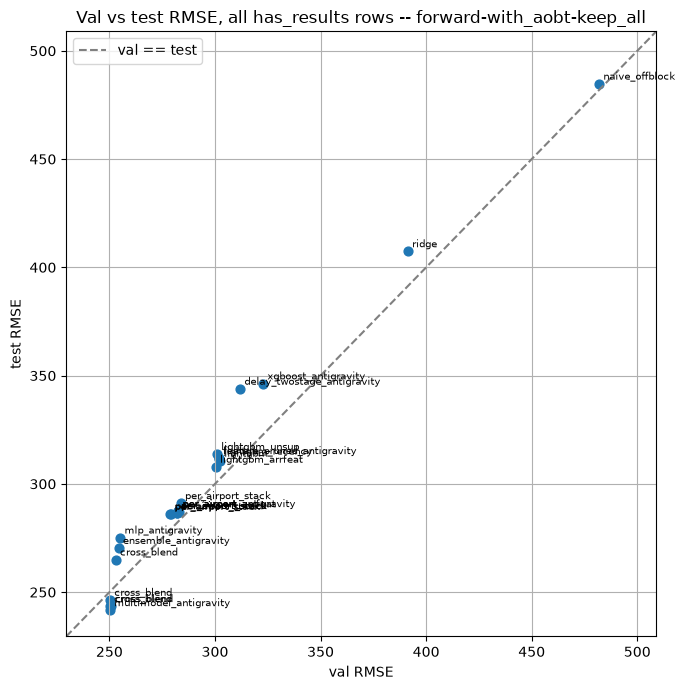

In [5]:
fig, ax = plt.subplots(figsize=(7, 7))
lims = [primary[["val_rmse", "test_rmse"]].min().min() * 0.95,
        primary[["val_rmse", "test_rmse"]].max().max() * 1.05]
ax.plot(lims, lims, "--", color="gray", label="val == test")
ax.scatter(primary["val_rmse"], primary["test_rmse"], s=40)
for _, r in primary.iterrows():
    ax.annotate(r["arm"], (r["val_rmse"], r["test_rmse"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("val RMSE"); ax.set_ylabel("test RMSE")
ax.set_title(f"Val vs test RMSE, all has_results rows -- {PRIMARY}")
ax.legend()
plt.tight_layout()
plt.show()


## 4. Seed-sweep stability

Arms run across all three sweep seeds (42/43/44) under the primary protocol --
a ranking that flips between seeds is noise, not a real difference (root
`CLAUDE.md`: "a single seed is not evidence of a ranking").


9 arms with >=2 seeds: ['ensemble_antigravity', 'lightgbm', 'mlp_antigravity', 'multimodel_antigravity', 'naive_offblock', 'per_airport', 'per_airport_antigravity', 'ridge', 'xgboost_antigravity']


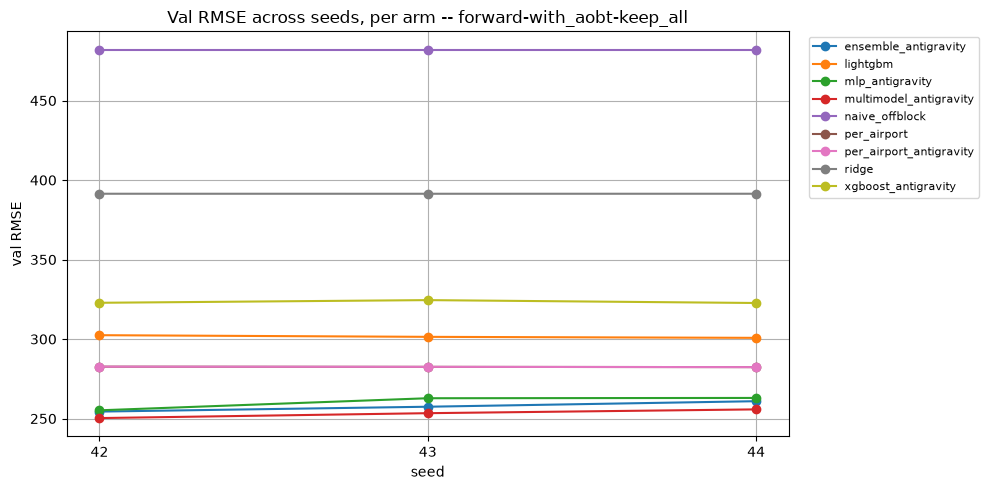

In [6]:
seed_sweep = df[(df.protocol == PRIMARY) & (df.status == "has_results") & df.tag.isna()]
counts = seed_sweep.groupby("arm")["seed"].nunique()
multi_seed_arms = counts[counts >= 2].index.tolist()
print(f"{len(multi_seed_arms)} arms with >=2 seeds: {multi_seed_arms}")

fig, ax = plt.subplots(figsize=(10, 5))
for arm in multi_seed_arms:
    sub = seed_sweep[seed_sweep.arm == arm].sort_values("seed")
    ax.plot(sub["seed"], sub["val_rmse"], marker="o", label=arm)
ax.set_xlabel("seed"); ax.set_ylabel("val RMSE")
ax.set_xticks([42, 43, 44])
ax.set_title(f"Val RMSE across seeds, per arm -- {PRIMARY}")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


## 5. Protocol sensitivity

How the arms that were actually run under more than one protocol move --
`with_aobt` vs `no_aobt` isolates the AOBT-proxy leakage question from
section-1's audit; the `winsor_*` / `drop_7200` variants isolate the outlier
-handling choice.


6 arms run under >=2 protocols: ['ensemble_antigravity', 'lightgbm', 'mlp_antigravity', 'naive_offblock', 'ridge', 'xgboost_antigravity']


protocol,forward-no_aobt-keep_all,forward-with_aobt-drop_7200,forward-with_aobt-keep_all,forward-with_aobt-winsor_21600,forward-with_aobt-winsor_7200,forward-with_aobt-winsor_p9999,seasonal-with_aobt-keep_all
arm,,,,,,,
ensemble_antigravity,258.56,NaN,254.40,NaN,NaN,325.39,246.04
lightgbm,307.87,358.28,302.45,323.67,341.19,329.42,291.69
mlp_antigravity,259.77,NaN,255.20,NaN,NaN,328.14,251.92
naive_offblock,427.94,482.03,481.97,481.98,481.98,481.98,477.83
ridge,393.07,391.45,391.41,377.74,385.61,383.27,395.43
xgboost_antigravity,324.76,NaN,322.83,NaN,NaN,340.66,341.69


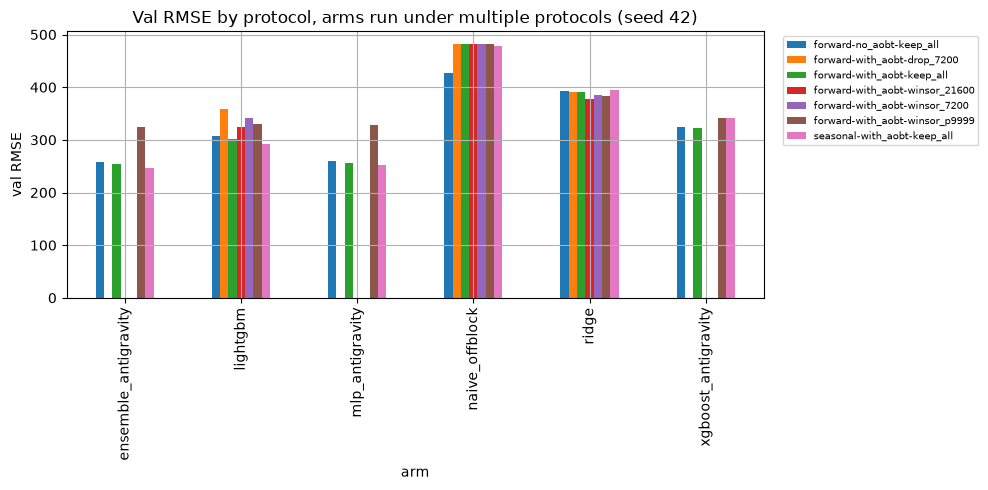

In [7]:
multi_protocol = df[df.status == "has_results"].groupby("arm")["protocol"].nunique()
arms_multi_proto = multi_protocol[multi_protocol >= 2].index.tolist()
print(f"{len(arms_multi_proto)} arms run under >=2 protocols: {arms_multi_proto}")

sub = df[(df.status == "has_results") & df.arm.isin(arms_multi_proto) & (df.seed == 42) & df.tag.isna()]
pivot = sub.pivot_table(index="arm", columns="protocol", values="val_rmse")
display(pivot)

if not pivot.empty:
    fig, ax = plt.subplots(figsize=(10, 5))
    pivot.plot.bar(ax=ax)
    ax.set_ylabel("val RMSE")
    ax.set_title("Val RMSE by protocol, arms run under multiple protocols (seed 42)")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
    plt.tight_layout()
    plt.show()


## 6. Build composition -- status and ownership

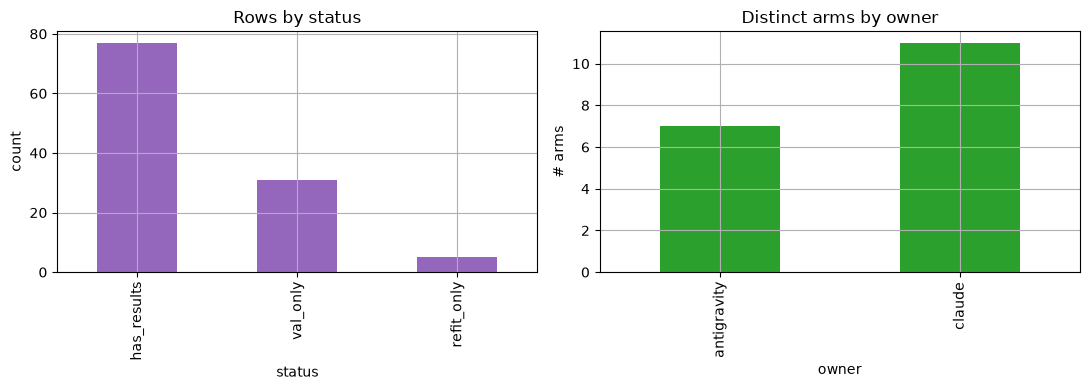

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

df["status"].value_counts().plot.bar(ax=axes[0], color="tab:purple")
axes[0].set_title("Rows by status")
axes[0].set_ylabel("count")

df.groupby("owner")["arm"].nunique().plot.bar(ax=axes[1], color="tab:green")
axes[1].set_title("Distinct arms by owner")
axes[1].set_ylabel("# arms")

plt.tight_layout()
plt.show()


## 7. Summary -- fill in after running

- Name the top 3 arms by val RMSE in section 2 and whether the val ranking survives on test.
- Section 3: flag any arm whose point sits noticeably off the diagonal -- name it and note whether its test set differs (e.g. `forward_inner` selection surface) before calling it overfit.
- Section 4: name any arm whose seed-42 rank would change under seed 43/44 -- that arm's margin over its neighbor is not yet established.
- Section 5: state, in one line, how much moving `with_aobt` -> `no_aobt` costs each arm it was run for -- that number is the practical price of NOT using the AOBT proxy, which is the leakage-risk trade-off Stage 1's audit exists to inform.

(Left for whoever runs the notebook to fill in with the printed numbers.)
